# Portfolio Risk Report: Commodities and Treasuries

---

### Notebook Map & Table of Contents

1. **Setup & Visualization Defaults**: Libraries, styling, and plot settings.
2. **Global Configuration & Settings**: All parameters consolidated into one central configuration cell.
3. **Data Ingestion & Hygiene**:
   - Defensive loading of 5 daily market CSV series with pandas only and actionable error messages.
   - Data cleaning (converting `.` to NaN, dropping missing values, parsing dates, sorting, removing duplicates).
   - Two date alignments: tradable prices (WTI, gold, IEF) for the risk model, and IEF with the two yields for Part E only.
   - April 2020 WTI negative price treatment (modelling assumption).
4. **Part A: Returns and Portfolio Construction**:
   - **Step 1**: Daily Percentage Returns & April 2020 WTI Zero-Return Treatment
   - **Step 2**: Portfolio Daily Return (Fixed Weights, Daily Rebalancing Simplification)
   - **Step 3**: Descriptive Statistics & Annualized Volatility
   - **Step 4**: Correlation Matrix Heatmap & 60-Day Rolling Correlations
5. **Part B: Value at Risk (VaR) and Expected Shortfall (ES)**:
   - **Step 5**: Historical VaR (95% and 99%)
   - **Step 6**: Parametric (Normal) VaR & The Bell Curve Assumption
   - **Step 7**: Monte Carlo VaR (Multivariate Normal Simulation)
   - **Step 8**: Expected Shortfall (CVaR / Tail Loss)
   - **Step 9**: Summary Comparison Table & Return Distribution Histogram
   - **Step 10**: 10-Day VaR & Square-Root-of-Time Scaling
6. **Part C: Is the Risk Model Reliable? (VaR Backtesting)**:
   - **Step 11**: Rolling 250-Day Historical VaR Backtest (Strictly No Look-Ahead)
   - **Step 12**: Backtest Calibration Diagnostic, Breach Rates & Annual Crisis Clustering
7. **Part D: Stress Tests & Scenario Analysis**:
   - **Step 13**: Historical Stress Windows (COVID Crash & 2022 Rate-Hike Year)
   - **Step 14**: Top 10 Worst Portfolio Days
   - **Step 15**: Forward-Looking Hypothetical Macro Shock Scenarios
8. **Part E: Fixed Income Mini-Section**:
   - **Step 16**: Yield Curve Slope (10Y - 2Y) & Recession Inversions
   - **Step 17**: Estimating IEF Yield Sensitivity (Duration Proxy Regression)
9. **Automated Sanity Checks**: 7 checks, including a real look-ahead test.
10. **My Findings**: Workspace for your findings and interview observations.
11. **Limitations**: Methodological limitations for interview discussion.


### Setup: Libraries & Imports

**WHAT:**
Imports basic Python data science libraries: `pandas`, `numpy`, `matplotlib.pyplot`, and `seaborn`.

**WHY:**
Restricting our stack to these foundational libraries keeps the code lightweight, beginner-friendly, and free from external dependencies or complex syntax.

**WATCH OUT:**
Avoid importing heavy or specialized packages (such as `scipy` or custom risk toolboxes) when simple NumPy and pandas functions can accomplish the calculations cleanly and transparently.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 15)


### Global Settings & Parameters (Consolidated Configuration)

**WHAT:**
Defines all global parameters in a single, centralized configuration cell:
- **Portfolio Value**: $\$1,000,000$ base equity.
- **Target Weights**: Equal allocation ($1/3$ each to WTI Crude Oil, Gold, and IEF Treasury ETF).
- **Confidence Levels**: $95\%$ and $99\%$.
- **Rolling Window**: $250$ trading days (approximately 1 calendar year) for out-of-sample backtesting.
- **Monte Carlo Simulations**: $10,000$ iterations with fixed random seed ($42$).
- **Named Historical Stress Windows**: The COVID Crash (2020-02-19 to 2020-03-23) and the 2022 Rate-Hike Year (2022-01-01 to 2022-12-31).
- **Forward-Looking Macro Shock Scenarios**: Scenario 1 (Energy & Market Selloff) and Scenario 2 (Stagflation / Supply Shock).





In [2]:
# 1. Portfolio capital and asset allocations
PORTFOLIO_VALUE = 1_000_000
WEIGHTS = {
    'wti': 1.0 / 3.0,
    'gold': 1.0 / 3.0,
    'ief': 1.0 / 3.0
}
CONFIDENCE_LEVELS = [0.95, 0.99]
ROLLING_WINDOW = 250

# 2. Monte Carlo simulation parameters
MC_SIMULATIONS = 10_000
RANDOM_SEED = 42

# 3. Historical stress testing windows
STRESS_WINDOWS = {
    'COVID Crash': ('2020-02-19', '2020-03-23'),
    '2022 Rate-Hike Year': ('2022-01-01', '2022-12-31')
}

# 4. Forward-looking hypothetical macro shock scenarios
SHOCK_SCENARIOS = {
    'Scenario 1: Energy & Market Selloff': {
        'wti': -0.20,
        'gold': -0.10,
        'ief': -0.05
    },
    'Scenario 2: Stagflation / Supply Shock': {
        'wti': 0.30,
        'gold': 0.05,
        'ief': -0.03
    }
}

print("All global parameters successfully consolidated and initialized:")
print(f"  Portfolio Capital: ${PORTFOLIO_VALUE:,.0f} | Weights: {WEIGHTS}")
print(f"  Confidence Levels: {CONFIDENCE_LEVELS} | Rolling Window: {ROLLING_WINDOW} days")
print(f"  MC Sims: {MC_SIMULATIONS:,} (Seed: {RANDOM_SEED})")


All global parameters successfully consolidated and initialized:
  Portfolio Capital: $1,000,000 | Weights: {'wti': 0.3333333333333333, 'gold': 0.3333333333333333, 'ief': 0.3333333333333333}
  Confidence Levels: [0.95, 0.99] | Rolling Window: 250 days
  MC Sims: 10,000 (Seed: 42)


### Data Ingestion: Defensive File Loading Helper

Defines `load_market_file(filepath, expected_cols)` to check whether a CSV file exists on disk and verify that all expected column headers are present before loading with pandas.




In [3]:
def load_market_file(filepath, expected_cols):
    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"ERROR: Missing file '{filepath}'.\n"
            f"Please ensure the file is downloaded into the 'data/' folder."
        )
    df = pd.read_csv(filepath)
    df.columns = [c.strip() for c in df.columns]
    missing = [c for c in expected_cols if c not in df.columns]
    if missing:
        raise ValueError(
            f"ERROR: File '{filepath}' is missing columns: {missing}.\n"
            f"Expected: {expected_cols}, Found: {list(df.columns)}"
        )
    return df


### Data Ingestion: Loading the 5 Raw Series

Loads the five required CSV files from `data/` using pandas only:
1. `data/wti.csv` — FRED `DCOILWTICO` (`observation_date`, `DCOILWTICO`)
2. `data/gold.csv` — Daily Gold Price (`date`, `price`)
3. `data/ief.csv` — IEF Treasury ETF (`date`, `price`)
4. `data/dgs10.csv` — FRED `DGS10` 10-Year Treasury Yield (`observation_date`, `DGS10`)
5. `data/dgs2.csv` — FRED `DGS2` 2-Year Treasury Yield (`observation_date`, `DGS2`)




In [4]:
raw_wti = load_market_file('data/wti.csv', ['observation_date', 'DCOILWTICO'])
raw_gold = load_market_file('data/gold.csv', ['date', 'price'])
raw_ief = load_market_file('data/ief.csv', ['date', 'price'])
raw_dgs10 = load_market_file('data/dgs10.csv', ['observation_date', 'DGS10'])
raw_dgs2 = load_market_file('data/dgs2.csv', ['observation_date', 'DGS2'])
print("All 5 raw data files successfully verified and loaded.")


All 5 raw data files successfully verified and loaded.


### Data Cleaning: Cleaning Helper Function

**WHAT:**
Defines `clean_series` to convert string `.` placeholders to `NaN`, convert values to numeric floats, drop missing observations, parse dates into standard `datetime` objects, sort chronologically, and remove duplicate dates.

**WHY:**
FRED series use `"."` to represent non-trading holidays. Converting these placeholders to `NaN` ensures the column becomes a numeric float series rather than an object series.

**WATCH OUT:**
Leaving string `"."` in a numeric column causes mathematical calculations like percentage change and standard deviation to fail.


In [5]:
def clean_series(df, date_col, val_col, new_val_name):
    clean_df = df[[date_col, val_col]].copy()
    clean_df[val_col] = pd.to_numeric(clean_df[val_col].replace('.', np.nan), errors='coerce')
    clean_df = clean_df.dropna(subset=[val_col])
    clean_df[date_col] = pd.to_datetime(clean_df[date_col])
    clean_df = clean_df.rename(columns={date_col: 'date', val_col: new_val_name})
    return clean_df.sort_values('date').drop_duplicates('date').reset_index(drop=True)


### Data Cleaning: Preprocessing All 5 Series

**WHAT:**
Applies `clean_series` to WTI, Gold, IEF, DGS10, and DGS2.

**WHY:**
Ensures every series is formatted consistently as `(date, value)` with clean numeric floats before joining.



In [6]:
wti_clean = clean_series(raw_wti, 'observation_date', 'DCOILWTICO', 'wti')
gold_clean = clean_series(raw_gold, 'date', 'price', 'gold')
ief_clean = clean_series(raw_ief, 'date', 'price', 'ief')
dgs10_clean = clean_series(raw_dgs10, 'observation_date', 'DGS10', 'dgs10')
dgs2_clean = clean_series(raw_dgs2, 'observation_date', 'DGS2', 'dgs2')
print(f"Cleaned counts - WTI: {len(wti_clean):,}, Gold: {len(gold_clean):,}, IEF: {len(ief_clean):,}")


Cleaned counts - WTI: 9,523, Gold: 3,771, IEF: 3,770


### Data Alignment: Two Inner Joins

**WHAT:**
Builds two aligned tables by inner join (a row is kept only if **every** series in that table has a value on that date):
- `market_data`: WTI, gold and IEF. Used for returns and the whole risk model.
- `rates_data`: IEF, DGS10 and DGS2. Used only in Part E (yield curve and IEF sensitivity).

**WHY:**
FRED has no Treasury yield on US bond-market holidays such as Columbus Day and Veterans Day, when stock exchanges are open. Putting yields in the portfolio table would delete valid trading days and turn the next day's return into a two-day return, which slightly distorts VaR. Keeping the yields in their own table avoids this.

**WATCH OUT:**
Outer joins introduce missing values (`NaN`) that corrupt return calculations and covariance matrices. An inner join is correct, but only across the series that the calculation actually needs.

In [7]:
def inner_join_all(series_list):
    merged = series_list[0]
    for s in series_list[1:]:
        merged = merged.merge(s, on='date', how='inner')
    return merged.sort_values('date').reset_index(drop=True)

# Portfolio table: only the three assets in the portfolio
market_data = inner_join_all([wti_clean, gold_clean, ief_clean])
# Rates table: IEF with the two Treasury yields (Part E only)
rates_data = inner_join_all([ief_clean, dgs10_clean, dgs2_clean])

print(f"Portfolio table (WTI, gold, IEF): {len(market_data):,} aligned days | "
      f"{market_data['date'].min().date()} to {market_data['date'].max().date()}")
print(f"Rates table (IEF, DGS10, DGS2):   {len(rates_data):,} aligned days | "
      f"{rates_data['date'].min().date()} to {rates_data['date'].max().date()}")

Portfolio table (WTI, gold, IEF): 3,735 aligned days | 2011-10-21 to 2026-10-14
Rates table (IEF, DGS10, DGS2):   3,741 aligned days | 2011-10-21 to 2026-10-19


### Step 1: Daily Percentage Returns & April 2020 WTI Negative Price Handling (Part A)

#### Formula & Simple Explanation
The daily percentage return measures the fractional price change:
$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$$

*Worked Example:*
If Gold closes at $\$100$ on Monday and $\$102$ on Tuesday:
$$R = \frac{102 - 100}{100} = +0.020 \quad (+2.0\%)$$

#### April 2020 WTI Negative Price Modelling Assumption
On April 20, 2020, the WTI spot price in this dataset (FRED/EIA) was **-$36.98 per barrel**; the expiring May futures contract settled at about -$37.63. The cause was a shortage of storage for physical delivery at Cushing, Oklahoma.

Percentage returns are mathematically undefined across negative prices because the denominator becomes negative. On April 21, 2020, when the price rebounded to $+\$8.91$, the standard formula would compute:
$$\frac{8.91 - (-36.98)}{-36.98} = \frac{45.89}{-36.98} = -1.2409 \quad (-124.09\%)$$
This mistakenly calculates a massive price surge as a negative return because the base was negative.

To prevent anomalous negative denominators from corrupting return math, we set WTI returns to zero on the negative-price day and the day after, print those dates, and explicitly note:

> **CRITICAL MODELLING ASSUMPTION:**
> Setting WTI returns to zero across negative prices is an explicit **modelling simplification** that allows standard percentage return mathematics to proceed. In reality, investors holding crude contracts on that day suffered catastrophic losses exceeding $100\%$ of invested equity. Consequently, setting these returns to zero **understates true tail risk** in historical distributions.

**WHAT:**
Computes daily fractional returns for WTI, Gold, and IEF, and applies the April 2020 zero-return fix to WTI.

**WHY:**
Stationary percentage returns are required for statistical risk modelling across assets with different unit prices.

**WATCH OUT:**
Leaving negative prices untouched in a percentage change calculation flips the mathematical sign of subsequent returns.


In [8]:
def compute_asset_returns(df):
    rets = pd.DataFrame({'date': df['date']})
    rets['wti'] = df['wti'].pct_change()
    rets['gold'] = df['gold'].pct_change()
    rets['ief'] = df['ief'].pct_change()
    
    # Identify and fix negative price observations
    neg_indices = df[df['wti'] < 0].index.tolist()
    for idx in neg_indices:
        d1 = df.loc[idx, 'date'].strftime('%Y-%m-%d')
        d2 = df.loc[idx + 1, 'date'].strftime('%Y-%m-%d')
        print(f"Modelling Assumption applied:")
        print(f"  Negative price day ({d1}): setting WTI return to 0.0")
        print(f"  Day after negative price ({d2}): setting WTI return to 0.0")
        rets.loc[idx, 'wti'] = 0.0
        rets.loc[idx + 1, 'wti'] = 0.0
        
    return rets.dropna().reset_index(drop=True)

returns_df = compute_asset_returns(market_data)
display(returns_df.head())


Modelling Assumption applied:
  Negative price day (2020-04-20): setting WTI return to 0.0
  Day after negative price (2020-04-21): setting WTI return to 0.0


,date,wti,gold,ief
0,2011-10-24,0.045074,0.010030,-0.000486
1,2011-10-25,0.020413,0.029125,0.008573
2,2011-10-26,-0.029899,0.013591,-0.007341
3,2011-10-27,0.041685,0.013932,-0.012066
4,2011-10-28,-0.006811,-0.000286,0.006007


*How to read this table:*
Each row represents one trading day. Values are decimal percentage returns (e.g. `0.01` indicates a $+1.0\%$ gain, while `-0.015` indicates a $-1.5\%$ loss).


### Step 2: Portfolio Daily Return & Daily Rebalancing Simplification

#### Formula & Simple Explanation
Portfolio daily return is the weighted sum of individual asset returns:
$$R_{p,t} = \sum_{i=1}^n w_i R_{i,t} = w_{\text{wti}} R_{\text{wti},t} + w_{\text{gold}} R_{\text{gold},t} + w_{\text{ief}} R_{\text{ief},t}$$

*Worked Example:*
Weights are $1/3$ each. If on a given day WTI moves $+3.0\%$ ($0.030$), Gold moves $+1.0\%$ ($0.010$), and IEF moves $-1.0\%$ ($-0.010$):
$$R_p = \left(\frac{1}{3} \times 0.030\right) + \left(\frac{1}{3} \times 0.010\right) + \left(\frac{1}{3} \times -0.010\right) = +0.010 \quad (+1.0\%)$$

> **MODELLING SIMPLIFICATION (Fixed Weights):**
> Keeping weights constant at 1/3 each day implies daily rebalancing where winning assets are trimmed and losing assets are bought at day-end with zero transaction costs.

**WHAT:**
Calculates the aggregate daily portfolio return across all dates using fixed equal weights.

**WHY:**
Forms the primary return series from which all downstream portfolio risk metrics are derived.

**WATCH OUT:**
Portfolio weights must sum to exactly $1.0$; otherwise unintended leverage or unallocated cash is introduced.


In [9]:
def add_portfolio_return(df, weights):
    assert np.isclose(sum(weights.values()), 1.0), "Weights must sum to 1.0"
    df['portfolio'] = (
        weights['wti'] * df['wti'] +
        weights['gold'] * df['gold'] +
        weights['ief'] * df['ief']
    )
    return df

returns_df = add_portfolio_return(returns_df, WEIGHTS)
display(returns_df.head())


,date,wti,gold,ief,portfolio
0,2011-10-24,0.045074,0.010030,-0.000486,0.018206
1,2011-10-25,0.020413,0.029125,0.008573,0.019370
2,2011-10-26,-0.029899,0.013591,-0.007341,-0.007883
3,2011-10-27,0.041685,0.013932,-0.012066,0.014517
4,2011-10-28,-0.006811,-0.000286,0.006007,-0.000363


*How to read this table:*
The `portfolio` column represents the daily return of the equal-weighted portfolio combining commodities and Treasuries.


### Step 3: Descriptive Statistics & Annualized Volatility

#### Formula & Simple Explanation
1. **Daily Volatility ($\sigma_{\text{daily}}$):** Standard deviation of daily returns.
2. **Annualized Volatility ($\sigma_{\text{ann}}$):** Because independent daily variances compound additively, annual variance is $252 \times \sigma_{\text{daily}}^2$. Taking the square root gives:
   $$\sigma_{\text{ann}} = \sigma_{\text{daily}} \times \sqrt{252}$$

*Worked Example:*
If an asset has daily volatility of $1.0\%$ ($0.010$):
$$\sigma_{\text{ann}} = 0.010 \times \sqrt{252} \approx 0.010 \times 15.8745 = 0.1587 \quad (15.87\%)$$

**WHAT:**
Builds a summary table showing annualized volatility, worst single day, best single day, 1st percentile, and 5th percentile for each asset and the blended portfolio.

**WHY:**
Provides an immediate comparison of volatility and tail risks across assets, highlighting how diversification dampens single-asset drawdowns.

**WATCH OUT:**
Do not use 365 calendar days; use 252 trading days for financial assets.


In [10]:
def get_series_stats(series):
    return {
        'Annualized Volatility': f"{series.std() * np.sqrt(252) * 100:.2f}%",
        'Worst Day': f"{series.min() * 100:.2f}%",
        'Best Day': f"{series.max() * 100:.2f}%",
        '1st Percentile': f"{series.quantile(0.01) * 100:.2f}%",
        '5th Percentile': f"{series.quantile(0.05) * 100:.2f}%"
    }

desc_stats = [
    {'Asset': c.upper(), **get_series_stats(returns_df[c])}
    for c in ['wti', 'gold', 'ief', 'portfolio']
]
display(pd.DataFrame(desc_stats))


,Asset,Annualized Volatility,Worst Day,Best Day,1st Percentile,5th Percentile
0,WTI,46.62%,-24.53%,53.09%,-7.12%,-3.77%
1,GOLD,17.16%,-10.78%,6.07%,-3.04%,-1.66%
2,IEF,6.41%,-2.51%,2.64%,-1.03%,-0.64%
3,PORTFOLIO,16.93%,-9.52%,18.60%,-2.48%,-1.41%


*How to read this table:*
Compare columns across rows: notice how the combined `PORTFOLIO` annualized volatility and worst day compare against the standalone assets, demonstrating the quantitative benefit of multi-asset diversification.


### Step 4: Asset Correlation Matrix (Heatmap)

#### Formula & Simple Explanation
Pearson correlation measures the strength and direction of linear co-movement between two assets:
$$\rho_{X,Y} = \frac{\text{Cov}(X,Y)}{\sigma_X \sigma_Y}$$

*Worked Example:*
A correlation near $0$ or negative means the assets provide strong diversification benefits to each other.

**WHAT:**
Plots the full-sample correlation matrix of WTI, Gold, and IEF as a Seaborn heatmap.

**WHY:**
Low correlation between commodities and Treasuries is the foundation of multi-asset portfolio construction.

**WATCH OUT:**
Full-sample correlation averages out market regimes and can mask temporary crisis correlation spikes.


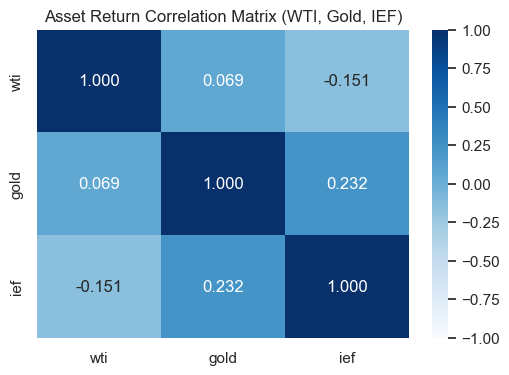

In [11]:
corr_mat = returns_df[['wti', 'gold', 'ief']].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr_mat, annot=True, fmt=".3f", cmap='Blues', vmin=-1, vmax=1)
plt.title("Asset Return Correlation Matrix (WTI, Gold, IEF)")
plt.show()


*How to read this chart:*
Values near $+1.0$ indicate lockstep co-movement; values near $0$ indicate independence; values below $0$ indicate hedging benefits.


### Step 4: 60-Day Rolling Correlations

**WHAT:**
Computes and plots 60-day rolling correlations between pairs: WTI-Gold, WTI-IEF, and Gold-IEF over time.

**WHY:**
Correlations are dynamic and fluctuate across macroeconomic regimes, especially during inflation spikes or liquidity crunches.

**WATCH OUT:**
Assuming correlations remain constant during crises is a classic risk management mistake.


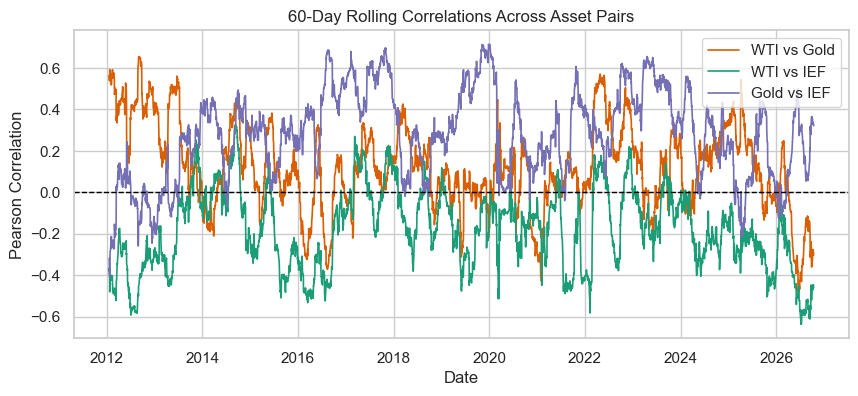

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(returns_df['date'], returns_df['wti'].rolling(60).corr(returns_df['gold']), label='WTI vs Gold', color='#d95f02', lw=1.2)
plt.plot(returns_df['date'], returns_df['wti'].rolling(60).corr(returns_df['ief']), label='WTI vs IEF', color='#1b9e77', lw=1.2)
plt.plot(returns_df['date'], returns_df['gold'].rolling(60).corr(returns_df['ief']), label='Gold vs IEF', color='#7570b3', lw=1.2)
plt.axhline(0, color='black', linestyle='--', lw=1)
plt.title("60-Day Rolling Correlations Across Asset Pairs")
plt.xlabel("Date")
plt.ylabel("Pearson Correlation")
plt.legend(loc='upper right')
plt.show()


*How to read this chart:*
Lines above zero show positive co-movement; lines below zero show hedging benefits. Notice how correlations fluctuate over time.


### Step 5: Historical Value at Risk (VaR) (Part B)

#### Formula & Simple Explanation
1-day Historical VaR at confidence level $c$ is the negative of the $(1-c)$ percentile of portfolio returns, multiplied by portfolio value:
$$\text{VaR}_{\text{Hist}}(c) = - q_{1-c}(R_p) \times \text{Portfolio Value}$$

*Worked Example:*
On a $\$1,000,000$ portfolio, if the 5th percentile return ($q_{0.05}$) is $-0.015$ ($-1.5\%$):
$$\text{VaR}_{\text{Hist}}(95\%) = - (-0.015) \times \$1,000,000 = +\$15,000$$
This means on $95\%$ of past days, the daily loss did not exceed $\$15,000$.

**WHAT:**
Computes 95% and 99% 1-day Historical VaR as positive dollar losses on $1,000,000.

**WHY:**
Historical VaR makes no assumption about distribution shape and directly reflects empirical history.

**WATCH OUT:**
Always report VaR as a positive dollar amount representing potential loss.


In [13]:
def calc_hist_var(series, port_val, conf_levels):
    res = {}
    for c in conf_levels:
        q = series.quantile(1.0 - c)
        dollar_loss = -q * port_val
        res[c] = {'cutoff': q, 'dollar_var': dollar_loss}
        print(f"Historical VaR {int(c*100)}%: Cutoff = {q*100:.2f}% | Loss = ${dollar_loss:,.2f}")
    return res

hist_var = calc_hist_var(returns_df['portfolio'], PORTFOLIO_VALUE, CONFIDENCE_LEVELS)


Historical VaR 95%: Cutoff = -1.41% | Loss = $14,088.51
Historical VaR 99%: Cutoff = -2.48% | Loss = $24,756.56


### Step 6: Parametric (Variance-Covariance) VaR

#### Formula & Simple Explanation
Assumes returns follow a Normal bell curve defined by mean $\mu$ and standard deviation $\sigma$:
$$R_{\text{cut}} = \mu - z \times \sigma$$
$$\text{VaR}_{\text{Param}} = - R_{\text{cut}} \times \text{Portfolio Value}$$
where $z = 1.645$ for 95% confidence and $z = 2.326$ for 99% confidence.

*Worked Example:*
If $\mu = 0.05\%$ ($0.0005$) and $\sigma = 1.0\%$ ($0.010$) on a $\$1,000,000$ portfolio:
$$R_{\text{cut}} = 0.0005 - (1.645 \times 0.010) = -0.01595 \quad (-1.595\%)$$
$$\text{VaR}_{\text{Param}}(95\%) = - (-0.01595) \times \$1,000,000 = +\$15,950$$

#### Why this assumes bell-shaped returns
The normal distribution assumes thin, symmetric tails. In reality, market returns exhibit fat tails (kurtosis > 3), meaning extreme crashes happen much more frequently than normal distributions estimate.

**WHAT:**
Calculates 1-day Parametric VaR at 95% and 99% confidence levels.

**WHY:**
Provides an analytical benchmark widely used across the industry.

**WATCH OUT:**
Parametric VaR often underestimates tail risk at high confidence levels like 99%.


In [14]:
def calc_param_var(series, port_val, z_map):
    mu, sigma = series.mean(), series.std()
    res = {}
    for c, z in z_map.items():
        q = mu - z * sigma
        dollar_loss = -q * port_val
        res[c] = {'cutoff': q, 'dollar_var': dollar_loss}
        print(f"Parametric VaR {int(c*100)}% (z={z}): Cutoff = {q*100:.2f}% | Loss = ${dollar_loss:,.2f}")
    return res

param_var = calc_param_var(returns_df['portfolio'], PORTFOLIO_VALUE, {0.95: 1.645, 0.99: 2.326})


Parametric VaR 95% (z=1.645): Cutoff = -1.72% | Loss = $17,205.48
Parametric VaR 99% (z=2.326): Cutoff = -2.45% | Loss = $24,468.61


### Step 7: Monte Carlo VaR (Multivariate Normal Simulation)

#### Formula & Simple Explanation
1. Estimate mean vector $\mathbf{\mu}$ and covariance matrix $\mathbf{\Sigma}$ of the 3 assets.
2. Simulate $10,000$ daily return draws using `np.random.multivariate_normal`.
3. Compute simulated portfolio return: $R_{p,\text{sim}} = \mathbf{w}^T \mathbf{R}_{\text{sim}}$.
4. Extract the 5th and 1st percentiles of simulated returns to find VaR.

*Worked Example:*
The 500th worst simulated return out of 10,000 (5th percentile) is $-1.62\%$. On $\$1,000,000$, Monte Carlo VaR is $\$16,200$.

**WHAT:**
Estimates VaR by simulating 10,000 joint asset return draws with fixed seed `42`.

**WHY:**
Monte Carlo simulation extends easily to non-linear portfolios and structured products.

**WATCH OUT:**
Always fix the random seed to ensure reproducibility.


In [15]:
def calc_mc_var(df, weights, port_val, n_sims, seed, conf_levels):
    np.random.seed(seed)
    assets = ['wti', 'gold', 'ief']
    sim_rets = np.random.multivariate_normal(df[assets].mean(), df[assets].cov(), size=n_sims)
    sim_port = sim_rets @ np.array([weights[a] for a in assets])
    res = {}
    for c in conf_levels:
        q = np.percentile(sim_port, (1.0 - c) * 100)
        dollar_loss = -q * port_val
        res[c] = {'cutoff': q, 'dollar_var': dollar_loss}
        print(f"Monte Carlo VaR {int(c*100)}%: Cutoff = {q*100:.2f}% | Loss = ${dollar_loss:,.2f}")
    return res

mc_var = calc_mc_var(returns_df, WEIGHTS, PORTFOLIO_VALUE, MC_SIMULATIONS, RANDOM_SEED, CONFIDENCE_LEVELS)


Monte Carlo VaR 95%: Cutoff = -1.72% | Loss = $17,237.33
Monte Carlo VaR 99%: Cutoff = -2.43% | Loss = $24,291.65


### Step 8: Expected Shortfall (CVaR / Tail Loss)

#### Formula & Simple Explanation
VaR answers: *"Where do the bad days begin?"*
Expected Shortfall (ES) answers: **"When a breach happens, how bad is the loss on average?"**

$$\text{ES}(c) = - \mathbb{E}\left[ R_p \mid R_p \le q_{1-c}(R_p) \right] \times \text{Portfolio Value}$$

*Worked Example:*
If the 95% VaR cutoff is $-2.0\%$ and the 5 days exceeding it averaged $-3.2\%$, the Expected Shortfall is $\$32,000$ (compared to $\$20,000$ for VaR).

**WHAT:**
Calculates 1-day Historical Expected Shortfall at 95% and 99% confidence levels.

**WHY:**
Expected Shortfall is a coherent risk measure that accounts for tail risk severity beyond VaR.

**WATCH OUT:**
Expected Shortfall must always be greater than or equal to VaR at the same confidence level.


In [16]:
def calc_expected_shortfall(series, port_val, conf_levels):
    res = {}
    for c in conf_levels:
        q = series.quantile(1.0 - c)
        tail_mean = series[series <= q].mean()
        dollar_es = -tail_mean * port_val
        res[c] = {'tail_mean': tail_mean, 'dollar_es': dollar_es}
        print(f"Historical ES {int(c*100)}%: Tail Mean = {tail_mean*100:.2f}% | Loss = ${dollar_es:,.2f}")
    return res

hist_es = calc_expected_shortfall(returns_df['portfolio'], PORTFOLIO_VALUE, CONFIDENCE_LEVELS)


Historical ES 95%: Tail Mean = -2.23% | Loss = $22,347.90
Historical ES 99%: Tail Mean = -3.77% | Loss = $37,688.61


### Step 9: Summary VaR & ES Comparison Table

**WHAT:**
Consolidates Historical VaR, Parametric VaR, Monte Carlo VaR, and Expected Shortfall into a clean comparison table.

**WHY:**
Enables side-by-side comparison of model assumptions and shows how empirical fat tails impact Expected Shortfall.

**WATCH OUT:**
Verify that 99% risk numbers exceed 95% numbers across all methods.


In [17]:
summary_rows = [
    {'Method': 'Historical VaR', '95% ($)': f"${hist_var[0.95]['dollar_var']:,.2f}", '99% ($)': f"${hist_var[0.99]['dollar_var']:,.2f}"},
    {'Method': 'Parametric VaR', '95% ($)': f"${param_var[0.95]['dollar_var']:,.2f}", '99% ($)': f"${param_var[0.99]['dollar_var']:,.2f}"},
    {'Method': 'Monte Carlo VaR', '95% ($)': f"${mc_var[0.95]['dollar_var']:,.2f}", '99% ($)': f"${mc_var[0.99]['dollar_var']:,.2f}"},
    {'Method': 'Expected Shortfall', '95% ($)': f"${hist_es[0.95]['dollar_es']:,.2f}", '99% ($)': f"${hist_es[0.99]['dollar_es']:,.2f}"}
]
display(pd.DataFrame(summary_rows))


,Method,95% ($),99% ($)
0,Historical VaR,"$14,088.51","$24,756.56"
1,Parametric VaR,"$17,205.48","$24,468.61"
2,Monte Carlo VaR,"$17,237.33","$24,291.65"
3,Expected Shortfall,"$22,347.90","$37,688.61"


*How to read this table:*
Contrasts potential dollar losses across methodologies. Notice that Expected Shortfall is substantially higher than VaR, capturing tail loss depth.


### Step 9: Portfolio Return Distribution Histogram

**WHAT:**
Plots the histogram of daily portfolio returns using an explicit color (`color="steelblue"`) to ensure compatibility across all Seaborn environments, and overlays vertical lines for 95% and 99% VaR and ES thresholds.

**WHY:**
Visually shows where risk thresholds lie on the actual return distribution.

**WATCH OUT:**
Always pass an explicit color argument to `sns.histplot` to prevent `ValueError: Invalid RGBA argument: None`.


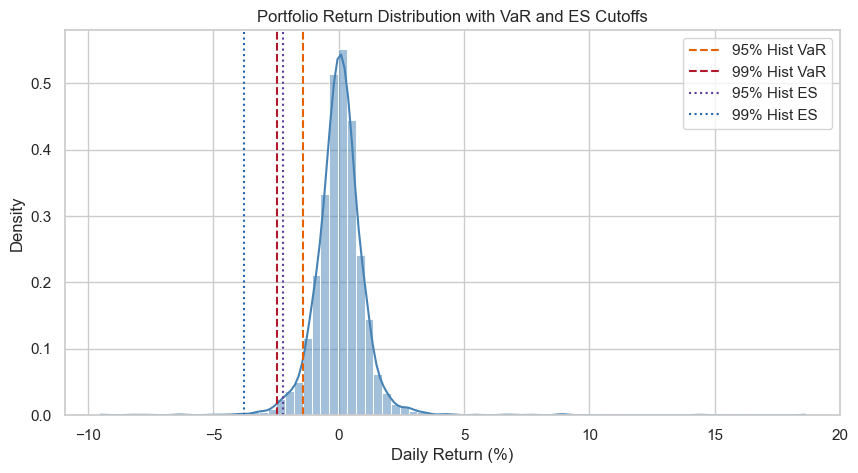

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(returns_df['portfolio'] * 100, bins=80, kde=True, stat='density', color='steelblue', alpha=0.5)
plt.axvline(hist_var[0.95]['cutoff'] * 100, color='#e66101', linestyle='--', label='95% Hist VaR')
plt.axvline(hist_var[0.99]['cutoff'] * 100, color='#b2182b', linestyle='--', label='99% Hist VaR')
plt.axvline(hist_es[0.95]['tail_mean'] * 100, color='#5e3c99', linestyle=':', label='95% Hist ES')
plt.axvline(hist_es[0.99]['tail_mean'] * 100, color='#2166ac', linestyle=':', label='99% Hist ES')
plt.title("Portfolio Return Distribution with VaR and ES Cutoffs")
plt.xlabel("Daily Return (%)")
plt.ylabel("Density")
plt.legend()
plt.show()


*How to read this chart:*
The dashed vertical lines mark the 95% and 99% VaR cutoff thresholds; the dotted lines mark the deeper Expected Shortfall average tail losses.


### Step 10: 10-Day VaR & Square-Root Scaling

#### Formula & Simple Explanation
Banks have traditionally scaled 1-day VaR to a 10-day horizon using the square root of time (newer market-risk rules lean on Expected Shortfall instead; check current rules before quoting them):
$$\text{VaR}_{\text{10-day}} = \text{VaR}_{\text{1-day}} \times \sqrt{10}$$

*Worked Example:*
If 1-day VaR is $\$15,000$, 10-day VaR is $\$15,000 \times \sqrt{10} \approx \$15,000 \times 3.1623 = \$47,434$.

#### When is this a poor approximation?
Square-root scaling assumes returns are independent and identically distributed (i.i.d.). This fails when:
1. Volatility clusters (high-volatility days follow high-volatility days).
2. Assets exhibit multi-day autocorrelation, trending, or mean-reversion.
3. Compounding produces fatter multi-day tails.

**WHAT:**
Calculates 10-day VaR across all three methods using $\sqrt{10}$ scaling.

**WHY:**
Gives a rough 10-day loss estimate from the 1-day number.

**WATCH OUT:**
Do not assume square-root scaling holds during market liquidity freezes.


In [19]:
sqrt10 = np.sqrt(10)
ten_day_rows = [
    {
        'Method': m,
        '1-Day 95% ($)': f"${v95:,.2f}",
        '10-Day 95% ($)': f"${v95 * sqrt10:,.2f}",
        '1-Day 99% ($)': f"${v99:,.2f}",
        '10-Day 99% ($)': f"${v99 * sqrt10:,.2f}"
    }
    for m, v95, v99 in [
        ('Historical', hist_var[0.95]['dollar_var'], hist_var[0.99]['dollar_var']),
        ('Parametric', param_var[0.95]['dollar_var'], param_var[0.99]['dollar_var']),
        ('Monte Carlo', mc_var[0.95]['dollar_var'], mc_var[0.99]['dollar_var'])
    ]
]
display(pd.DataFrame(ten_day_rows))


,Method,1-Day 95% ($),10-Day 95% ($),1-Day 99% ($),10-Day 99% ($)
0,Historical,"$14,088.51","$44,551.78","$24,756.56","$78,287.13"
1,Parametric,"$17,205.48","$54,408.51","$24,468.61","$77,376.55"
2,Monte Carlo,"$17,237.33","$54,509.22","$24,291.65","$76,816.93"


*How to read this table:*
Shows the 10-day capital requirement calculated by multiplying 1-day VaR by $\sqrt{10} \approx 3.162$.


### Step 11: VaR Backtest (Rolling 250-Day Window, No Look-Ahead) (Part C)

#### Formula & Simple Explanation
For every trading day $t$ (starting after an initial 250-day window):
1. Take strictly the **prior 250 trading days** (from day $t-250$ to $t-1$).
2. Calculate the 5th percentile (95% cutoff) and 1st percentile (99% cutoff).
3. **Breach Definition:** A breach occurs if today's actual portfolio return is worse than the cutoff:
   $$\text{Breach on day } t \iff R_{p,t} < \text{Cutoff}_t$$

*Worked Example:*
If yesterday's 250-day window predicted a 95% VaR cutoff of $-1.5\%$, and today the portfolio drops $-2.1\%$, today is a breach.

#### Avoiding Look-Ahead Bias
Today's return ($R_{p,t}$) is **strictly excluded** from the rolling window used to compute today's risk.

**WHAT:**
Executes a walk-forward rolling 250-day Historical VaR backtest across the entire historical series.

**WHY:**
Backtesting checks whether the loss numbers a model promises match what actually happened.

**WATCH OUT:**
Including today's return in today's window artificially hides crash breaches.


In [20]:
def run_rolling_backtest(df, window):
    p_rets = df['portfolio'].values
    q95_list, q99_list = [], []
    for i in range(window, len(p_rets)):
        hist_window = p_rets[i - window : i]
        q95_list.append(np.percentile(hist_window, 5.0))
        q99_list.append(np.percentile(hist_window, 1.0))
    b_df = df.iloc[window:].copy().reset_index(drop=True)
    b_df['var95_cut'] = q95_list
    b_df['var99_cut'] = q99_list
    b_df['breach_95'] = b_df['portfolio'] < b_df['var95_cut']
    b_df['breach_99'] = b_df['portfolio'] < b_df['var99_cut']
    return b_df

backtest_df = run_rolling_backtest(returns_df, ROLLING_WINDOW)
print(f"Backtest completed over {len(backtest_df):,} out-of-sample trading days.")


Backtest completed over 3,484 out-of-sample trading days.


### Step 12: Backtest Calibration Diagnostic (How Many Breaches Is Too Many?)

#### Formulas and simple explanation
If a 95% VaR model is right, about 5% of days should be breaches; for a 99% model, about 1%. Even a perfect model will not hit exactly 5.00%, so the question is: *how far off is too far off?*

1. **Expected breaches** $= N \times p$, where $N$ is the number of days and $p$ is $0.05$ or $0.01$.
   *Worked example:* 1,000 days at 99% gives $1{,}000 \times 0.01 = 10$ expected breaches.
2. **z-score** $= \dfrac{x - Np}{\sqrt{Np(1-p)}}$, with $x$ the actual number of breaches. It counts how many "normal wiggles" the actual count is away from the expected one.
   *Worked example:* 16 breaches against 10 expected: the wiggle is $\sqrt{1000 \times 0.01 \times 0.99} \approx 3.15$, so $z = (16 - 10)/3.15 \approx 1.9$. A value beyond about $\pm 2$ is unlikely to be chance.
3. **Kupiec test (a standard backtest test):**
$$LR = -2\ln\!\left[(1-p)^{N-x}\,p^{x}\right] + 2\ln\!\left[\left(1-\tfrac{x}{N}\right)^{N-x}\left(\tfrac{x}{N}\right)^{x}\right]$$
   It compares how likely the data is if the model is right versus if the true breach rate were exactly what we saw. A value **above 3.84** means the breach count is too far from expected to blame on chance (5% significance).
   *Worked example:* the same 16 breaches against 10 expected give $LR \approx 3.08$, below 3.84, so that count would be accepted.

**WHAT:**
Counts breaches at both confidence levels, then reports expected breaches, the z-score, the Kupiec statistic and a plain-English verdict.

**WHY:**
A breach rate near 5% or 1% is a **diagnostic**, not an assumption. If breaches are well above expected, the model understates risk; well below, it overstates it.

**WATCH OUT:**
Both tests assume breaches are independent, but breaches **cluster** in crises, so these tests make a bad count look *more* surprising than it really is. A passing result does not prove the model is good, and the 99% level has few expected breaches, so it needs more data to judge.

In [21]:
def kupiec_lr(breaches, n_days, p):
    rate = min(max(breaches / n_days, 1e-12), 1 - 1e-12)
    log_model = (n_days - breaches) * np.log(1 - p) + breaches * np.log(p)
    log_actual = (n_days - breaches) * np.log(1 - rate) + breaches * np.log(rate)
    return -2.0 * (log_model - log_actual)


total_days = len(backtest_df)
calib_rows = []
for label, col, p in [('95%', 'breach_95', 0.05), ('99%', 'breach_99', 0.01)]:
    x = int(backtest_df[col].sum())
    expected = total_days * p
    z = (x - expected) / np.sqrt(total_days * p * (1 - p))
    lr = kupiec_lr(x, total_days, p)
    if lr < 3.84:
        verdict = 'Consistent with the model'
    elif x > expected:
        verdict = 'Too many breaches (risk understated)'
    else:
        verdict = 'Too few breaches (risk overstated)'
    calib_rows.append({
        'VaR level': label, 'Days': total_days, 'Breaches': x,
        'Expected': round(expected, 1), 'Breach rate': f"{x / total_days:.2%}",
        'z-score': round(z, 2), 'Kupiec LR': round(lr, 2), 'Verdict': verdict,
    })

calibration_table = pd.DataFrame(calib_rows)
calibration_table

,VaR level,Days,Breaches,Expected,Breach rate,z-score,Kupiec LR,Verdict
0,95%,3484,192,174.2,5.51%,1.38,1.86,Consistent with the model
1,99%,3484,50,34.8,1.44%,2.58,5.87,Too many breaches (risk understated)


### Step 12: Backtest Returns vs Dynamic VaR Bounds Plot

**WHAT:**
Plots daily portfolio returns alongside dynamic rolling 95% and 99% VaR threshold lines, marking breach days with red dots.

**WHY:**
Visualizes the dynamic adaptation of the risk bounds and clearly reveals when breaches occurred over the multi-year sample.

**WATCH OUT:**
Observe whether breaches are evenly distributed across time or bunch up during market drops.


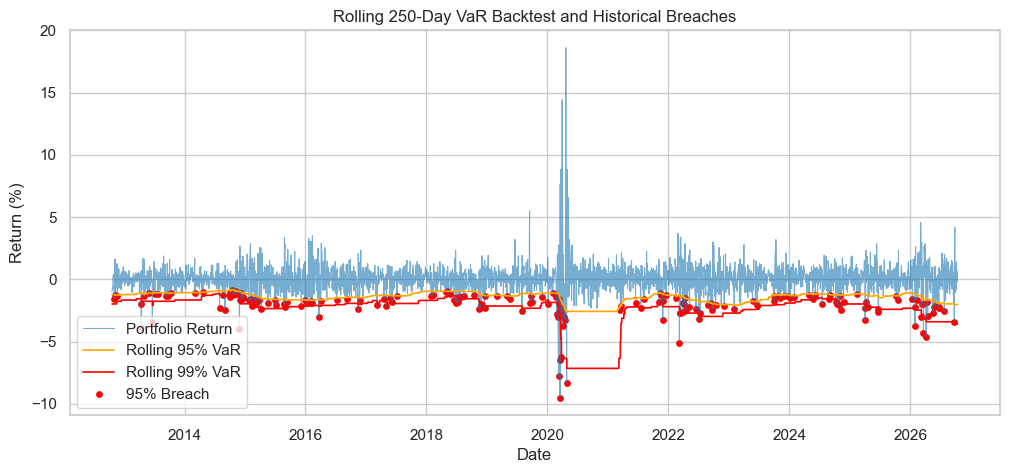

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(backtest_df['date'], backtest_df['portfolio'] * 100, lw=0.8, alpha=0.6, label='Portfolio Return', color='#1f77b4')
plt.plot(backtest_df['date'], backtest_df['var95_cut'] * 100, color='orange', lw=1.2, label='Rolling 95% VaR')
plt.plot(backtest_df['date'], backtest_df['var99_cut'] * 100, color='red', lw=1.2, label='Rolling 99% VaR')
b95_pts = backtest_df[backtest_df['breach_95']]
plt.scatter(b95_pts['date'], b95_pts['portfolio'] * 100, color='red', s=15, label='95% Breach')
plt.title("Rolling 250-Day VaR Backtest and Historical Breaches")
plt.xlabel("Date")
plt.ylabel("Return (%)")
plt.legend(loc='lower left')
plt.show()


*How to read this chart:*
The orange and red lines trace daily risk thresholds. Red dots show days where actual losses breached the 95% VaR model.


### Step 12: Annual Breach Distribution (Crisis Clustering Analysis)

**WHAT:**
Groups backtest breaches by calendar year and plots an annual bar chart.

**WHY:**
Tests whether breaches occur independently or cluster heavily in systemic crises (such as the 2014-2015 oil crash, 2020 COVID shock, and 2022 rate hikes).

**WATCH OUT:**
Breach clustering is an empirical market reality, not a programming bug.


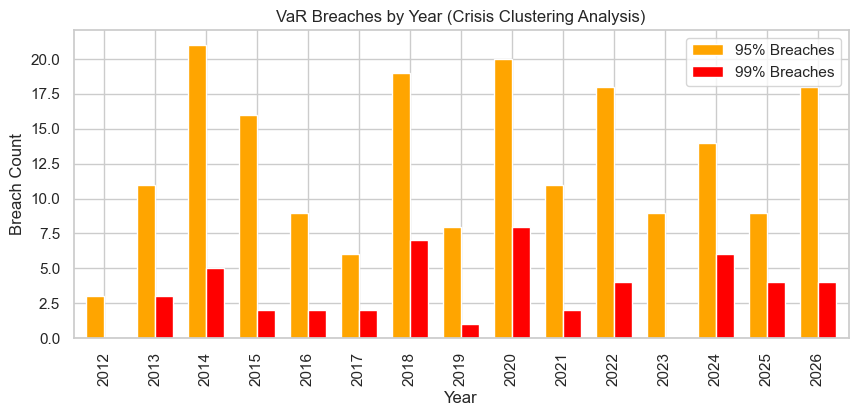

In [23]:
backtest_df['year'] = backtest_df['date'].dt.year
by_year = backtest_df.groupby('year')[['breach_95', 'breach_99']].sum()
by_year.plot(kind='bar', figsize=(10, 4), color=['orange', 'red'], width=0.7)
plt.title("VaR Breaches by Year (Crisis Clustering Analysis)")
plt.xlabel("Year")
plt.ylabel("Breach Count")
plt.legend(['95% Breaches', '99% Breaches'])
plt.show()


*How to read this chart:*
Taller bars indicate years where volatility surged faster than the 250-day rolling window could adapt, causing breach clusters during crisis periods.


### Step 13: Stress Testing Named Windows (Part D)

#### Formula & Simple Explanation
Measures compounded cumulative return and dollar loss across historical crisis windows:
$$\text{Cumulative Return} = \prod_{t=1}^T (1 + R_t) - 1$$
$$\text{Dollar P&L} = \text{Cumulative Portfolio Return} \times \text{Portfolio Value}$$

*Worked Example:*
If an asset drops $-10\%$ on day 1 and $-10\%$ on day 2:
$$\text{Cum Return} = (1 - 0.10) \times (1 - 0.10) - 1 = 0.90 \times 0.90 - 1 = -0.19 \quad (-19.0\%)$$
On $\$1,000,000$, the loss is $\$190,000$.

Returns are compounded from the day **after** the start date, so the window runs from the start date's closing price to the end date's closing price.

Windows tested:
1. **COVID Crash (2020-02-19 to 2020-03-23)**
2. **2022 Rate-Hike Year (2022-01-01 to 2022-12-31)**

**WHAT:**
Calculates cumulative return for each asset and portfolio, along with dollar loss on $1,000,000.

**WHY:**
Shows how the multi-asset portfolio would have survived historical market drawdowns.

**WATCH OUT:**
Never sum percentage returns; always compound them using `prod(1 + r) - 1`.


In [24]:
def eval_stress_window(df, start, end, port_val):
    sub = df[(df['date'] > start) & (df['date'] <= end)]
    cum_p = np.prod(1.0 + sub['portfolio']) - 1.0
    return {
        'Dates': f"{start} to {end}",
        'WTI': f"{(np.prod(1.0 + sub['wti']) - 1.0) * 100:.2f}%",
        'Gold': f"{(np.prod(1.0 + sub['gold']) - 1.0) * 100:.2f}%",
        'IEF': f"{(np.prod(1.0 + sub['ief']) - 1.0) * 100:.2f}%",
        'Portfolio': f"{cum_p * 100:.2f}%",
        'Dollar P&L': f"${cum_p * port_val:,.2f}"
    }

stress_records = [
    {'Window': name, **eval_stress_window(returns_df, s, e, PORTFOLIO_VALUE)}
    for name, (s, e) in STRESS_WINDOWS.items()
]
display(pd.DataFrame(stress_records))


,Window,Dates,WTI,Gold,IEF,Portfolio,Dollar P&L
0,COVID Crash,2020-02-19 to 2020-03-23,-56.24%,-2.52%,6.38%,-20.21%,"$-202,141.09"
1,2022 Rate-Hike Year,2022-01-01 to 2022-12-31,6.41%,-0.13%,-15.16%,-0.88%,"$-8,813.26"


*How to read this table:*
Shows total multi-week compounded returns for each asset and the blended portfolio, along with the net dollar P&L on a $\$1,000,000$ portfolio.


### Step 14: Top 10 Worst Portfolio Days

**WHAT:**
Extracts the 10 worst single-day portfolio returns in history, showing each asset's return on that same day.

**WHY:**
Identifies which asset triggered the loss and whether the other assets provided diversification buffer or fell together.

**WATCH OUT:**
An individual asset's worst day does not always match the portfolio's worst day if other assets offset the loss.


In [25]:
worst10 = returns_df.sort_values('portfolio').head(10).copy()
worst_table = pd.DataFrame({
    'Date': worst10['date'].dt.strftime('%Y-%m-%d'),
    'Portfolio': (worst10['portfolio'] * 100).round(2).astype(str) + '%',
    'Dollar Loss': (-worst10['portfolio'] * PORTFOLIO_VALUE).round(2).apply(lambda x: f"${x:,.2f}"),
    'WTI': (worst10['wti'] * 100).round(2).astype(str) + '%',
    'Gold': (worst10['gold'] * 100).round(2).astype(str) + '%',
    'IEF': (worst10['ief'] * 100).round(2).astype(str) + '%'
})
display(worst_table)


,Date,Portfolio,Dollar Loss,WTI,Gold,IEF
2089,2020-03-18,-9.52%,"$95,150.69",-24.04%,-3.12%,-1.39%
2116,2020-04-27,-8.37%,"$83,650.48",-23.89%,-0.67%,-0.53%
2082,2020-03-09,-7.8%,"$78,025.24",-24.53%,0.22%,0.9%
2091,2020-03-20,-6.48%,"$64,821.81",-22.36%,0.37%,2.55%
2095,2020-03-26,-6.22%,"$62,224.86",-20.0%,1.09%,0.24%
2585,2022-03-09,-5.1%,"$51,027.77",-11.99%,-2.7%,-0.62%
3602,2026-04-08,-4.62%,"$46,241.32",-16.07%,1.97%,0.22%
3591,2026-03-23,-4.28%,"$42,832.85",-9.5%,-3.66%,0.32%
775,2014-11-28,-3.98%,"$39,766.69",-10.53%,-1.79%,0.39%
368,2013-04-15,-3.95%,"$39,502.78",-2.72%,-9.35%,0.22%


*How to read this table:*
Ranks the top 10 single-day portfolio losses in history, showing each asset's simultaneous return to pinpoint the primary loss driver.


### Step 15: Forward-Looking Macro Shock Scenarios

#### Formula & Simple Explanation
Hypothetical instantaneous shocks to portfolio value:
$$\Delta P = \sum_{i=1}^n w_i \times s_i \times \text{Portfolio Value}$$

*Worked Example:*
Equal weights ($1/3$ each) on $\$1,000,000$. If Oil drops $-20\%$, Gold $-10\%$, and IEF $-5\%$:
$$\text{Loss} = \left(\frac{1}{3} \times -0.20 + \frac{1}{3} \times -0.10 + \frac{1}{3} \times -0.05\right) \times \$1,000,000 = -\$116,667$$

**WHAT:**
Applies the two macro shock scenarios defined in settings to calculate immediate percentage impact and dollar P&L.

**WHY:**
Evaluates forward-looking "what-if" vulnerabilities beyond historical events.

**WATCH OUT:**
Always weight the shocks by asset allocation.


In [26]:
def eval_shocks(shocks, weights, port_val):
    rows = []
    for name, sc in shocks.items():
        ret = sum(weights[a] * sc[a] for a in ['wti', 'gold', 'ief'])
        rows.append({
            'Scenario': name,
            'WTI Shock': f"{sc['wti'] * 100:+.1f}%",
            'Gold Shock': f"{sc['gold'] * 100:+.1f}%",
            'IEF Shock': f"{sc['ief'] * 100:+.1f}%",
            'Portfolio Return': f"{ret * 100:+.2f}%",
            'Dollar P&L': f"${ret * port_val:+,.2f}"
        })
    return pd.DataFrame(rows)

display(eval_shocks(SHOCK_SCENARIOS, WEIGHTS, PORTFOLIO_VALUE))


,Scenario,WTI Shock,Gold Shock,IEF Shock,Portfolio Return,Dollar P&L
0,Scenario 1: Energy & Market Selloff,-20.0%,-10.0%,-5.0%,-11.67%,"$-116,666.67"
1,Scenario 2: Stagflation / Supply Shock,+30.0%,+5.0%,-3.0%,+10.67%,"$+106,666.67"


*How to read this table:*
Shows the immediate portfolio percentage return and dollar P&L under hypothetical macroeconomic shocks.


### Step 16: Yield Curve Slope Calculation (DGS10 - DGS2) (Part E)

#### Formula & Simple Explanation
The yield curve slope is the difference between 10-year and 2-year Treasury yields in **percentage points**:
$$\text{Slope}_t = \text{DGS10}_t - \text{DGS2}_t$$

*Worked Example:*
If 10Y yield is $3.80\%$ and 2Y yield is $4.60\%$, $\text{Slope} = 3.80 - 4.60 = -0.80$ percentage points (**Inverted curve**).
Historically, an inverted yield curve has been a leading indicator of economic recessions.

**WHAT:**
Computes daily yield curve slope in percentage points and reports count and share of inverted days.

**WHY:**
Yield curve shifts directly drive bond returns (IEF) and signal broader economic cycle shifts.

**WATCH OUT:**
Slope is in percentage points, not a percentage return.


In [27]:
slope = rates_data['dgs10'] - rates_data['dgs2']
inv_days = (slope < 0).sum()
pct_inv = (inv_days / len(rates_data)) * 100
print("=== Treasury Yield Curve Slope Summary (10Y - 2Y) ===")
print(f"Total Trading Days: {len(rates_data):,}")
print(f"Inverted Days (Slope < 0): {inv_days:,} ({pct_inv:.2f}% of total sample)")


=== Treasury Yield Curve Slope Summary (10Y - 2Y) ===
Total Trading Days: 3,741
Inverted Days (Slope < 0): 543 (14.51% of total sample)


### Step 16: Yield Curve Slope & Inversion Regimes Plot

**WHAT:**
Plots the yield curve slope over time with a zero line and shaded red areas when inverted ($	ext{Slope} < 0$).

**WHY:**
Visually highlights historical inversion regimes (e.g. 2019, 2022–2024).

**WATCH OUT:**
Clearly identify the zero boundary to distinguish normal from inverted regimes.


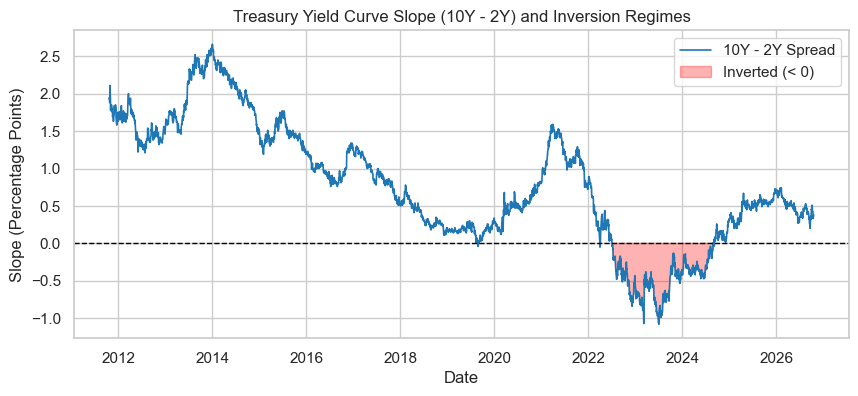

In [28]:
plt.figure(figsize=(10, 4))
plt.plot(rates_data['date'], slope, lw=1.2, label='10Y - 2Y Spread', color='#1f77b4')
plt.axhline(0, color='black', linestyle='--', lw=1)
plt.fill_between(rates_data['date'], slope, 0, where=(slope < 0), color='red', alpha=0.3, label='Inverted (< 0)')
plt.title("Treasury Yield Curve Slope (10Y - 2Y) and Inversion Regimes")
plt.xlabel("Date")
plt.ylabel("Slope (Percentage Points)")
plt.legend()
plt.show()


*How to read this chart:*
The blue line shows the 10Y-2Y Treasury spread in percentage points. Shaded red areas mark periods when the yield curve was inverted, indicating monetary tightening and elevated recession risk.


### Step 17: Estimating IEF Yield Sensitivity (Duration Proxy Regression)

#### Formula & Simple Explanation
Bond prices move inversely to bond yields. A bond portfolio's **duration** measures its percentage price change for a 1 percentage-point change in yield:
$$\frac{\Delta P}{P} \approx - \text{Duration} \times \Delta y$$

We estimate this empirically by regressing IEF daily percentage returns against daily changes in 10-year Treasury yields (in percentage points) using `np.polyfit`:
$$R_{\text{ief}, t} (\%) = \alpha + \beta \times \Delta \text{DGS10}_t (\text{pp}) + \epsilon_t$$

*Worked Example:*
If IEF has a duration of approximately $7$:
A $+1.0$ percentage-point rise in 10Y yield costs about $-7\%$ in bond price. The regression slope $\beta$ will be approximately $-7$.

> **NOTE:**
> The empirical regression slope is an econometric statistical proxy for price sensitivity based on daily trading data. It does not claim to equal published effective duration (which depends on exact underlying bond cash flows, convexities, and coupon adjustments).

**WHAT:**
Regresses IEF daily return on daily change in 10-year yield using `np.polyfit`, prints the empirical slope, and explains the duration intuition.

**WHY:**
Equips risk analysts with an empirical rule of thumb for interest rate risk in fixed income holdings.

**WATCH OUT:**
Regressing price levels on yield levels rather than returns on yield changes produces a spurious non-stationary regression.


In [29]:
ief_ret_pct = rates_data['ief'].pct_change() * 100.0
delta_dgs10 = rates_data['dgs10'].diff()
valid = ~(ief_ret_pct.isna() | delta_dgs10.isna())
x = delta_dgs10[valid].values
y = ief_ret_pct[valid].values

slope_coef, intercept = np.polyfit(x, y, 1)
print("=== IEF Yield Sensitivity Regression ===")
print(f"Empirical Slope (Beta): {slope_coef:.3f} % per pp change in yield")
print(f"Intercept: {intercept:.4f} %")
print(f"Interpretation: A +1.00 pp rise in 10Y yield corresponds to approximately a {slope_coef:.2f}% daily return on IEF.")


=== IEF Yield Sensitivity Regression ===
Empirical Slope (Beta): -7.602 % per pp change in yield
Intercept: 0.0121 %
Interpretation: A +1.00 pp rise in 10Y yield corresponds to approximately a -7.60% daily return on IEF.


### Step 17: IEF Yield Sensitivity Scatter Plot & Regression Line

**WHAT:**
Plots the daily scatter of 10-year yield changes versus IEF returns, overlaying the fitted linear regression line.

**WHY:**
Visually demonstrates the inverse relationship between Treasury yields and bond prices.

**WATCH OUT:**
Ensure the regression line slopes downward, confirming that bond prices fall as yields rise.


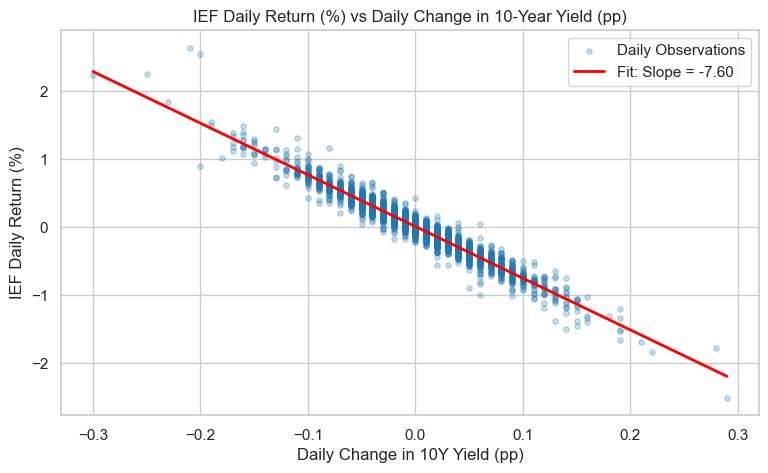

In [30]:
plt.figure(figsize=(9, 5))
plt.scatter(x, y, alpha=0.25, s=15, color='#1f77b4', label='Daily Observations')
x_grid = np.linspace(x.min(), x.max(), 100)
plt.plot(x_grid, slope_coef * x_grid + intercept, color='red', lw=2, label=f"Fit: Slope = {slope_coef:.2f}")
plt.title("IEF Daily Return (%) vs Daily Change in 10-Year Yield (pp)")
plt.xlabel("Daily Change in 10Y Yield (pp)")
plt.ylabel("IEF Daily Return (%)")
plt.legend()
plt.show()


*How to read this chart:*
Each blue dot is one trading day. The red downward slope illustrates the inverse relationship between Treasury yields and bond prices, with the slope indicating empirical duration sensitivity.


### Automated Sanity Checks (7 Checks)

**WHAT:**
Runs seven automatic checks. Each one stops the notebook with an error message if it fails:
1. **Weights:** portfolio weights sum to 1.0.
2. **Missing data:** no missing values in either aligned table.
3. **Signs:** VaR and Expected Shortfall are positive dollar losses.
4. **ES vs VaR:** Expected Shortfall is at least as large as VaR at both levels.
5. **Confidence order:** 99% VaR exceeds 95% VaR for all three methods.
6. **Hand check:** the 5th percentile, recomputed by hand from the sorted returns, equals the Historical VaR cutoff.
7. **Look-ahead test:** change one day's return to an extreme value and re-run the backtest. Every VaR cutoff up to and including that day must be unchanged, and the next day's cutoff must change.

**WHY:**
Quiet mistakes produce neat-looking numbers. Check 7 is a real test: if today's return leaked into today's VaR, the cutoff would move when we change it.

**WATCH OUT:**
A check only proves what it tests. These checks do not prove the model is a good forecast. The calibration table (Step 12) is what tells you that.

In [31]:
print("=" * 65)
print("PORTFOLIO RISK MODEL: AUTOMATED SANITY CHECKS")
print("=" * 65)

# 1. Weights
w_sum = sum(WEIGHTS.values())
assert np.isclose(w_sum, 1.0), f"FAILED: weights sum to {w_sum}"
print(f"  [PASS 1/7] Weights sum to {w_sum:.4f}.")

# 2. Missing data
nulls = market_data.isna().sum().sum() + rates_data.isna().sum().sum()
assert nulls == 0, f"FAILED: {nulls} missing values"
print(f"  [PASS 2/7] No missing values (portfolio rows: {len(market_data):,}, rates rows: {len(rates_data):,}).")

# 3. Signs
for c in [0.95, 0.99]:
    assert hist_var[c]['dollar_var'] > 0 and hist_es[c]['dollar_es'] > 0, f"FAILED: non-positive loss at {c}"
print("  [PASS 3/7] VaR and ES are positive dollar losses.")

# 4. ES >= VaR
for c in [0.95, 0.99]:
    assert hist_es[c]['dollar_es'] >= hist_var[c]['dollar_var'], f"FAILED: ES < VaR at {c}"
print("  [PASS 4/7] Expected Shortfall >= VaR at both levels.")

# 5. 99% > 95% for every method
for name, res in [('Historical', hist_var), ('Parametric', param_var), ('Monte Carlo', mc_var)]:
    assert res[0.99]['dollar_var'] > res[0.95]['dollar_var'], f"FAILED: {name} 99% <= 95%"
print("  [PASS 5/7] 99% VaR > 95% VaR for all three methods.")

# 6. Hand check: 5th percentile by linear interpolation on the sorted returns
sorted_r = np.sort(returns_df['portfolio'].values)
pos = 0.05 * (len(sorted_r) - 1)
low = int(np.floor(pos))
hand_cut = sorted_r[low] + (pos - low) * (sorted_r[low + 1] - sorted_r[low])
assert np.isclose(hand_cut, hist_var[0.95]['cutoff']), "FAILED: hand percentile differs"
print(f"  [PASS 6/7] Hand-computed 5th percentile {hand_cut:.5f} equals the Historical VaR cutoff.")

# 7. Look-ahead test: perturb one day, see which cutoffs move
test_df = returns_df.copy()
start_i = max(ROLLING_WINDOW + 100, 600)
day_i = int(test_df.index[(test_df.index >= start_i) & (test_df['portfolio'] > 0.005)][0])
test_df.loc[day_i, 'portfolio'] = -0.50
perturbed = run_rolling_backtest(test_df, ROLLING_WINDOW)
row_i = day_i - ROLLING_WINDOW                       # backtest row of the changed day
same_up_to_day = np.allclose(backtest_df['var95_cut'].values[:row_i + 1], perturbed['var95_cut'].values[:row_i + 1])
changes_next = backtest_df['var95_cut'].values[row_i + 1] != perturbed['var95_cut'].values[row_i + 1]
assert same_up_to_day, "FAILED: a cutoff on or before the changed day moved (look-ahead!)"
assert changes_next, "FAILED: the next day's cutoff did not react to the changed return"
assert len(backtest_df) == len(returns_df) - ROLLING_WINDOW, "FAILED: backtest length"
print(f"  [PASS 7/7] Look-ahead test: changing day {day_i} left all earlier cutoffs unchanged and moved the next one.")
print("=" * 65)
print("ALL 7 SANITY CHECKS PASSED.")
print("=" * 65)

PORTFOLIO RISK MODEL: AUTOMATED SANITY CHECKS
  [PASS 1/7] Weights sum to 1.0000.
  [PASS 2/7] No missing values (portfolio rows: 3,735, rates rows: 3,741).
  [PASS 3/7] VaR and ES are positive dollar losses.
  [PASS 4/7] Expected Shortfall >= VaR at both levels.
  [PASS 5/7] 99% VaR > 95% VaR for all three methods.
  [PASS 6/7] Hand-computed 5th percentile -0.01409 equals the Historical VaR cutoff.
  [PASS 7/7] Look-ahead test: changing day 612 left all earlier cutoffs unchanged and moved the next one.
ALL 7 SANITY CHECKS PASSED.


## My Findings


### 1. Diversification helped against oil, but barely against gold
- Annualized volatility: WTI 46.6%, gold 17.2%, IEF 6.4%, equal-weight portfolio 16.9%. The portfolio is far calmer than oil but only slightly calmer than gold alone.
- The worst portfolio day was -9.52% on 2020-03-18, against a worst WTI day of -24.53% on 2020-03-09.
- **In 9 of the 10 worst portfolio days WTI fell 9.5% or more**; the exception is 2013-04-15, when gold fell 9.35%. Oil is the main source of tail risk in this portfolio.

### 2. VaR methods and the fat-tail evidence
- 95% one-day VaR on $1,000,000: historical $14,089, parametric $17,205, Monte Carlo $17,237. The normal curve **overstates** the 95% loss, because real returns are more peaked in the middle.
- 99% VaR: historical $24,757, parametric $24,469, Monte Carlo $24,292. The three methods look alike here, so VaR alone hides the tail.
- **Expected Shortfall shows the tail:** $22,348 at 95% and $37,689 at 99%, which is 1.59 and 1.52 times the historical VaR. A normal curve would give roughly 1.25 and 1.15, so the real tail is much heavier.

### 3. Backtest: 95% passes, 99% understates risk
- Over 3,484 tested days, 95% VaR had 192 breaches against 174.2 expected (z-score 1.38, Kupiec 1.86), which is consistent with the model.
- 99% VaR had 50 breaches against 34.8 expected (z-score 2.58, Kupiec 5.87, above the 3.84 threshold). **The model understates tail risk.**
- Breaches cluster in turbulent years: the 95% breach count ranges from 3 (2012) to 21 (2014) a year, against about 12.6 expected, and 8 of the 50 breaches at 99% fell in 2020. A rolling window reacts slowly when volatility jumps.

### 4. Stress tests
- **COVID window:** portfolio -20.21% ($-202,141.09); WTI -56.24%, gold -2.52%, IEF 6.38%. The bond rally cushioned part of the oil collapse.
- **2022:** IEF -15.16% and WTI 6.41% left the portfolio at only -0.88%. Oil's rise offset the bond loss that year, but that was a feature of that year, not a guaranteed hedge (see the rolling correlations).
- **Worst days:** 5 of the 10 worst days fall in March-April 2020; the rest are spread across 2013, 2014, 2022 and 2026.
- The two shock scenarios are hypothetical sensitivities, not forecasts.

### 5. Fixed income
- The 10Y minus 2Y curve was inverted on 543 days (14.5% of the sample), almost all of them (540) in 2022-2024.
- The IEF regression slope is -7.60% per percentage-point rise in the 10-year yield, in the range one expects for a 7-10 year Treasury fund. It is an estimate, not the published duration, partly because the yield and the ETF price are recorded at different times of day.

## Limitations

### spot, futures and ETF proxies
- WTI is a **spot** series (FRED/EIA), not a futures contract. A real position would roll futures and face roll yield (a cost in contango, a gain in backwardation), margin and financing.
- IEF is an ETF with fees and small tracking differences from the underlying bond index (check the fund's current expense ratio).
- Gold is Yahoo Finance's continuous front-month COMEX gold futures series (`GC=F`), not the London (LBMA) fixing. A continuous series stitches successive contracts together, so small price gaps at contract rolls can sit inside the returns (check whether the series is roll-adjusted before relying on it for strategy work).
- The three assets are priced on different calendars and at different times of day: WTI spot (EIA), gold futures (CME) and IEF (stock exchange).

### fixed weights
- Equal weights are rebalanced every day with no transaction costs, taxes or slippage. Real weights drift as prices move.

### normal-distribution assumption
- Parametric and Monte Carlo VaR assume bell-shaped returns. This data has much heavier tails, as the Expected Shortfall to VaR ratios and the 99% backtest show.
- Correlations are not constant: assets that diversify in calm periods can fall together in a liquidity crunch.

### one 15-year sample
- The sample runs from October 2011 to October 2026. It includes near-zero interest rates, the 2020 pandemic shock and the 2022 rate-hike cycle, but not the 2008 crisis or the 1970s. Covariances and VaR depend on which regimes are in the window.

### WTI April 2020 treatment
- WTI spot was negative on 20 April 2020, so percentage returns are undefined. Setting the returns to zero on that day and the next is a **modelling assumption** and understates the true tail loss a futures holder suffered.

### backtest tests
- The z-score and Kupiec test assume independent breaches. Breaches cluster in crises, so these tests make a bad count look more surprising than it is, and a pass does not prove the model is good.